In [1]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 68.2 MB/s eta 0:00:00


In [2]:
import os
import re
import json
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

from gensim.models import Word2Vec

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Embedding, LSTM, Bidirectional
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

## 1. Load dataset

In [3]:
CSV_FILE = "flipitnews.csv"
url = "https://drive.google.com/uc?id=1POmzYEQZgZVqJO3F_cyNcd4QmoNE_mCv"

if not os.path.exists(CSV_FILE):
    try:
        import gdown
        gdown.download(url, CSV_FILE, quiet=False)
    except Exception as e:
        print("Dataset download failed:", e)

if not os.path.exists(CSV_FILE):
    raise FileNotFoundError(
        "flipitnews.csv was not found. Upload it to Colab or place it beside this notebook."
    )

# The file is tab-separated. Keep the original column names so we can select
# the actual news text rather than the filename (e.g. 001.txt).
df = pd.read_csv(CSV_FILE, sep="\t")
df.columns = [str(c).strip().lower() for c in df.columns]
print("Dataset columns:", df.columns.tolist())
print(df.head(3))
print("Original shape:", df.shape)

# Select the label and real article text robustly.
category_candidates = ["category", "label", "class", "target"]
category_col = next((c for c in category_candidates if c in df.columns), None)
if category_col is None:
    raise ValueError(f"Could not find a category/label column. Found: {df.columns.tolist()}")

# Prefer full article content; title is added when available.
content_col = next((c for c in ["content", "article", "text", "body", "news"] if c in df.columns), None)
title_col = next((c for c in ["title", "headline"] if c in df.columns), None)

if content_col is None and title_col is None:
    raise ValueError(
        "Could not find article text. Expected a column such as 'content', 'article', or 'title'."
    )

df["Category"] = df[category_col].astype(str).str.strip().str.lower()
if content_col and title_col:
    df["Article"] = (
        df[title_col].fillna("").astype(str).str.strip() + ". " +
        df[content_col].fillna("").astype(str).str.strip()
    ).str.strip(" .")
elif content_col:
    df["Article"] = df[content_col].fillna("").astype(str)
else:
    df["Article"] = df[title_col].fillna("").astype(str)

df = df[["Category", "Article"]]
print("\\nSelected text column(s):", [c for c in [title_col, content_col] if c])
print("Shape:", df.shape)
print(df[["Category", "Article"]].head(3))


Downloading...
From: https://drive.google.com/uc?id=1POmzYEQZgZVqJO3F_cyNcd4QmoNE_mCv
To: /content/flipitnews.csv
100%|██████████| 5.08M/5.08M [00:00<00:00, 13.0MB/s]

Dataset columns: ['category', 'filename', 'title', 'content']
   category filename                              title  \
0  business  001.txt  Ad sales boost Time Warner profit   
1  business  002.txt   Dollar gains on Greenspan speech   
2  business  003.txt  Yukos unit buyer faces loan claim   

                                             content  
0   Quarterly profits at US media giant TimeWarne...  
1   The dollar has hit its highest level against ...  
2   The owners of embattled Russian oil giant Yuk...  
Original shape: (2225, 4)
\nSelected text column(s): ['title', 'content']
Shape: (2225, 2)
   Category                                            Article
0  business  Ad sales boost Time Warner profit. Quarterly p...
1  business  Dollar gains on Greenspan speech. The dollar h...
2  business  Yukos unit buyer faces loan claim. The owners ...


## 2. EDA


Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  2225 non-null   object
 1   Article   2225 non-null   object
dtypes: object(2)
memory usage: 34.9+ KB

Missing values:
Category    0
Article     0
dtype: int64
Shape after cleaning: (2127, 2)

Category counts:
Category
sport            505
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


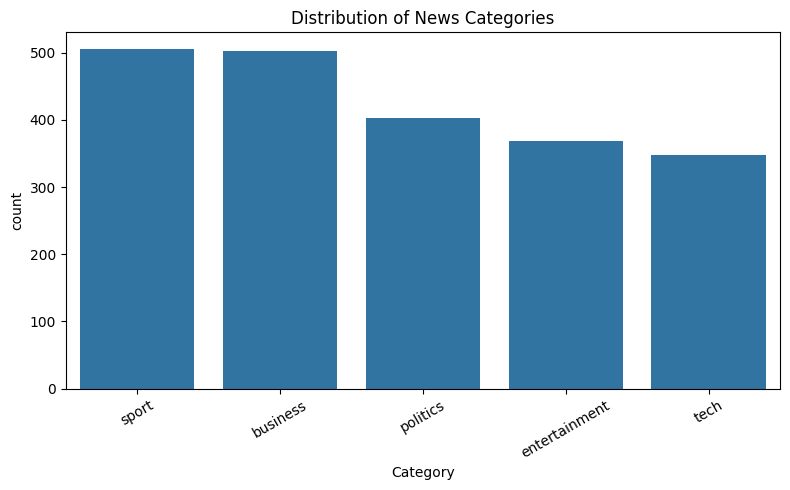


Average words per article: 384.11095439586273


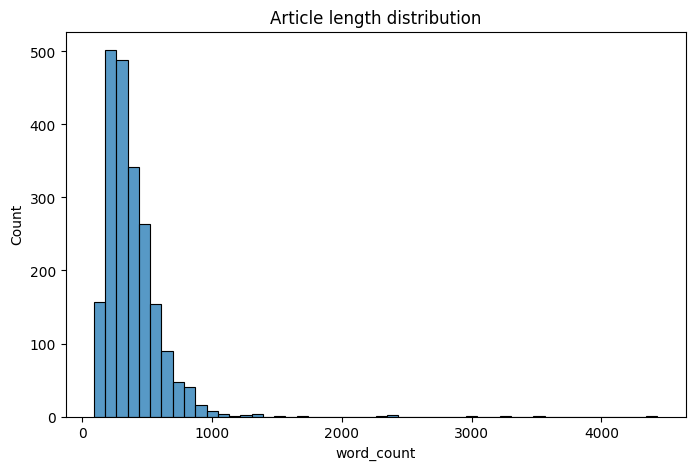

In [4]:
print("\nInfo:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


df = df.dropna()
df = df.drop_duplicates()
df = df.reset_index(drop=True)
print("Shape after cleaning:", df.shape)

print("\nCategory counts:")
print(df['Category'].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(x='Category', data=df, order=df['Category'].value_counts().index)
plt.title("Distribution of News Categories")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("category_distribution.png")
plt.show()


df['word_count'] = df['Article'].apply(lambda x: len(str(x).split()))
print("\nAverage words per article:", df['word_count'].mean())

plt.figure(figsize=(8, 5))
sns.histplot(df['word_count'], bins=50)
plt.title("Article length distribution")
plt.savefig("article_length.png")
plt.show()

## 3. Preprocessing

In [5]:
try:
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words("english"))
except Exception:
    stop_words = set(ENGLISH_STOP_WORDS)

print("Number of stopwords:", len(stop_words))

def clean_text(text):
    # Normalize punctuation/numbers, then remove common stopwords.
    # This function now receives the article title + full content, not filename.
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    tokens = [w for w in tokens if len(w) > 1 and w not in stop_words]
    return tokens

df["Article"] = df["Article"].fillna("").astype(str)
df = df[df["Article"].str.strip().ne("")].copy()
df["tokens"] = df["Article"].apply(clean_text)
df["clean_text"] = df["tokens"].apply(lambda x: " ".join(x))
df = df[df["clean_text"].str.strip().ne("")].copy()

print("\\nOriginal article:", df["Article"].iloc[0][:250])
print("Cleaned article :", df["clean_text"].iloc[0][:250])

le = LabelEncoder()
df["label"] = le.fit_transform(df["Category"])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))
print("Class counts:\\n", df["Category"].value_counts())

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["label"]
)
y_train = train_df["label"].values
y_test = test_df["label"].values
print("Train:", len(train_df), "Test:", len(test_df))

results = {}

def get_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    return acc, prec, rec, f1

def build_nn(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(256, activation="relu"),
        Dropout(0.4),
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(num_classes, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def make_early_stopping():
    return EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )


Number of stopwords: 198
\nOriginal article: Ad sales boost Time Warner profit. Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from 
Cleaned article : ad sales boost time warner profit quarterly profits us media giant timewarner jumped bn three months december year earlier firm one biggest investors google benefited sales high speed internet connections higher advert sales timewarner said fourth qu
Classes: ['business', 'entertainment', 'politics', 'sport', 'tech']
Class counts:\n Category
sport            505
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64
Train: 1701 Test: 426


## 4. Bag of Words + NN

In [6]:
print("\\n===== TF-IDF + Linear SVM (recommended text-classification baseline) =====")
from sklearn.svm import LinearSVC

# Word and two-word phrase features are usually strong for news categorization.
tfidf_svm = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)
X_train_svm = tfidf_svm.fit_transform(train_df["clean_text"])
X_test_svm = tfidf_svm.transform(test_df["clean_text"])

svm_model = LinearSVC(C=1.0, class_weight="balanced", random_state=42)
svm_model.fit(X_train_svm, y_train)
svm_pred = svm_model.predict(X_test_svm)
results["TF-IDF + LinearSVC"] = get_metrics(y_test, svm_pred)
print("Accuracy, Precision, Recall, F1:", results["TF-IDF + LinearSVC"])
print(classification_report(
    y_test, svm_pred, labels=np.arange(num_classes),
    target_names=le.classes_, zero_division=0
))

print("\\n===== Bag of Words + NN =====")
bow = CountVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2)
X_train_bow = bow.fit_transform(train_df["clean_text"]).toarray().astype("float32")
X_test_bow = bow.transform(test_df["clean_text"]).toarray().astype("float32")

nn_bow = build_nn(X_train_bow.shape[1])
nn_bow.fit(
    X_train_bow, y_train, epochs=20, batch_size=32,
    validation_split=0.1, callbacks=[make_early_stopping()], verbose=1
)
pred = np.argmax(nn_bow.predict(X_test_bow, verbose=0), axis=1)
results["BoW + NN"] = get_metrics(y_test, pred)
print(results["BoW + NN"])


\n===== TF-IDF + Linear SVM (recommended text-classification baseline) =====
Accuracy, Precision, Recall, F1: (0.9882629107981221, 0.988556338028169, 0.9882629107981221, 0.9882847460757991)
               precision    recall  f1-score   support

     business       1.00      0.97      0.98       101
entertainment       0.99      0.99      0.99        74
     politics       0.99      0.99      0.99        81
        sport       1.00      1.00      1.00       101
         tech       0.96      1.00      0.98        69

     accuracy                           0.99       426
    macro avg       0.99      0.99      0.99       426
 weighted avg       0.99      0.99      0.99       426

\n===== Bag of Words + NN =====
Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - accuracy: 0.8353 - loss: 0.5375 - val_accuracy: 0.9942 - val_loss: 0.0283
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9954 - loss: 0.0249 - val_accuracy: 1.0000 - val_loss: 0.0144
Epoch 3/20
48/48 ━━━━━━━━━━

## 5. TF-IDF + NN

In [7]:
print("\\n===== TF-IDF + NN =====")
tfidf = TfidfVectorizer(
    max_features=15000, ngram_range=(1, 2), min_df=2, sublinear_tf=True
)
X_train_tfidf = tfidf.fit_transform(train_df["clean_text"]).toarray().astype("float32")
X_test_tfidf = tfidf.transform(test_df["clean_text"]).toarray().astype("float32")

nn_tfidf = build_nn(X_train_tfidf.shape[1])
nn_tfidf.fit(
    X_train_tfidf, y_train, epochs=20, batch_size=32,
    validation_split=0.1, callbacks=[make_early_stopping()], verbose=1
)
pred = np.argmax(nn_tfidf.predict(X_test_tfidf, verbose=0), axis=1)
results["TF-IDF + NN"] = get_metrics(y_test, pred)
print(results["TF-IDF + NN"])


\n===== TF-IDF + NN =====
Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.6837 - loss: 1.1252 - val_accuracy: 0.9883 - val_loss: 0.3150
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9915 - loss: 0.1035 - val_accuracy: 1.0000 - val_loss: 0.0346
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9993 - loss: 0.0119 - val_accuracy: 0.9942 - val_loss: 0.0239
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0053 - val_accuracy: 1.0000 - val_loss: 0.0136
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0031 - val_accuracy: 0.9942 - val_loss: 0.0151
Epoch 6/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 0.0127
Epoch 7/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.9942 - val_loss: 0.0125
Epoch 8/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0012 - val_a

## 6. Word2Vec + NN (average of word vectors)

In [8]:
print("\\n===== Word2Vec + NN (average of word vectors) =====")
w2v_model = Word2Vec(
    sentences=train_df["tokens"].tolist(),
    vector_size=100, window=5, min_count=2, workers=4, seed=42, epochs=20
)

def doc_vector(tokens):
    vecs = [w2v_model.wv[w] for w in tokens if w in w2v_model.wv]
    if not vecs:
        return np.zeros(100, dtype="float32")
    return np.mean(vecs, axis=0).astype("float32")

X_train_w2v = np.array([doc_vector(t) for t in train_df["tokens"]], dtype="float32")
X_test_w2v = np.array([doc_vector(t) for t in test_df["tokens"]], dtype="float32")

nn_w2v = build_nn(100)
nn_w2v.fit(
    X_train_w2v, y_train, epochs=30, batch_size=32,
    validation_split=0.1, callbacks=[make_early_stopping()], verbose=1
)
pred = np.argmax(nn_w2v.predict(X_test_w2v, verbose=0), axis=1)
results["Word2Vec + NN"] = get_metrics(y_test, pred)
print(results["Word2Vec + NN"])


\n===== Word2Vec + NN (average of word vectors) =====
Epoch 1/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.8111 - loss: 0.6410 - val_accuracy: 0.9825 - val_loss: 0.0923
Epoch 2/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9458 - loss: 0.1659 - val_accuracy: 0.9883 - val_loss: 0.0499
Epoch 3/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9497 - loss: 0.1422 - val_accuracy: 0.9883 - val_loss: 0.0393
Epoch 4/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9614 - loss: 0.1232 - val_accuracy: 0.9883 - val_loss: 0.0364
Epoch 5/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9588 - loss: 0.1266 - val_accuracy: 0.9883 - val_loss: 0.0423
Epoch 6/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9627 - loss: 0.1123 - val_accuracy: 0.9883 - val_loss: 0.0398
Epoch 7/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9641 - loss: 0.1015 - val_accuracy: 0.9883 - val_loss: 0.0334
Epoch 8/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0

## 7. RNN (Embedding + Bi-LSTM)

\n===== RNN (Embedding + Bi-LSTM) =====


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 400, 96)        │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 96)             │        55,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,982,213 (7.56 MB)

 Trainable params: 1,982,213 (7.56 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
48/48 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.3235 - loss: 1.5194 - val_accuracy: 0.4912 - val_loss: 1.5453
Epoch 2/12
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5895 - loss: 1.1068 - val_accuracy: 0.6374 - val_loss: 0.9603
Epoch 3/12
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8399 - loss: 0.5301 - val_accuracy: 0.7953 - val_loss: 0.5054
Epoch 4/12
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9340 - loss: 0.2603 - val_accuracy: 0.9298 - val_loss: 0.2363
Epoch 5/12
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9725 - loss: 0.1289 - val_accuracy: 0.9123 - val_loss: 0.2512
Epoch 6/12
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9627 - loss: 0.1385 - val_accuracy: 0.9357 - val_loss: 0.2259
Epoch 7/12
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9987 - loss: 0.0247 - val_accuracy: 0.9825 - val_loss: 0.0717
Epoch 8/12
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 1.0000 - loss: 0.0062 - val_accuracy: 0.9825 - v

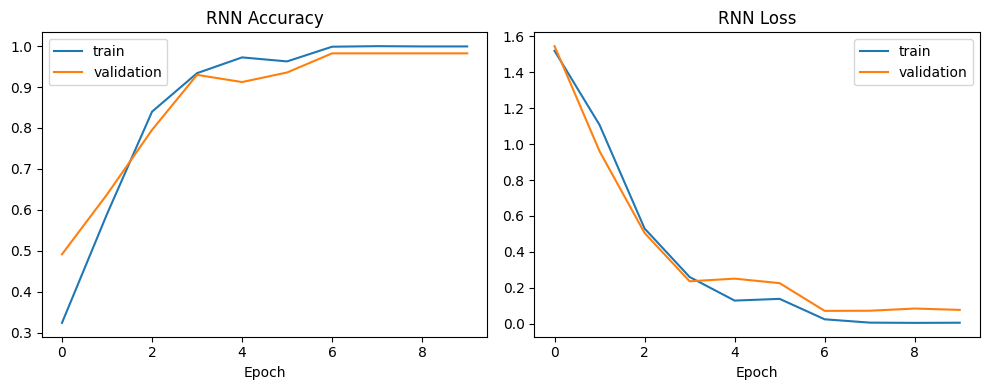

In [9]:
print("\\n===== RNN (Embedding + Bi-LSTM) =====")
max_words = 20000
max_len = 400

tok = Tokenizer(num_words=max_words, oov_token="<OOV>")
tok.fit_on_texts(train_df["clean_text"])

X_train_seq = pad_sequences(
    tok.texts_to_sequences(train_df["clean_text"]),
    maxlen=max_len, padding="post", truncating="post"
)
X_test_seq = pad_sequences(
    tok.texts_to_sequences(test_df["clean_text"]),
    maxlen=max_len, padding="post", truncating="post"
)

rnn = Sequential([
    Input(shape=(max_len,)),
    Embedding(max_words, 96, mask_zero=True),
    Bidirectional(LSTM(48)),
    Dropout(0.4),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])
rnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
rnn.summary()

history = rnn.fit(
    X_train_seq, y_train, epochs=12, batch_size=32,
    validation_split=0.1, callbacks=[make_early_stopping()], verbose=1
)

rnn_pred = np.argmax(rnn.predict(X_test_seq, verbose=0), axis=1)
results["RNN (Bi-LSTM)"] = get_metrics(y_test, rnn_pred)
print("Accuracy, Precision, Recall, F1:", results["RNN (Bi-LSTM)"])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("RNN Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("RNN Loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.savefig("rnn_training.png")
plt.show()


\n===== Model Comparison (sorted by F1-score) =====
                    Accuracy  Precision  Recall  F1-score
TF-IDF + NN           0.9883     0.9885  0.9883    0.9883
TF-IDF + LinearSVC    0.9883     0.9886  0.9883    0.9883
BoW + NN              0.9836     0.9838  0.9836    0.9836
Word2Vec + NN         0.9812     0.9815  0.9812    0.9812
RNN (Bi-LSTM)         0.9531     0.9542  0.9531    0.9531


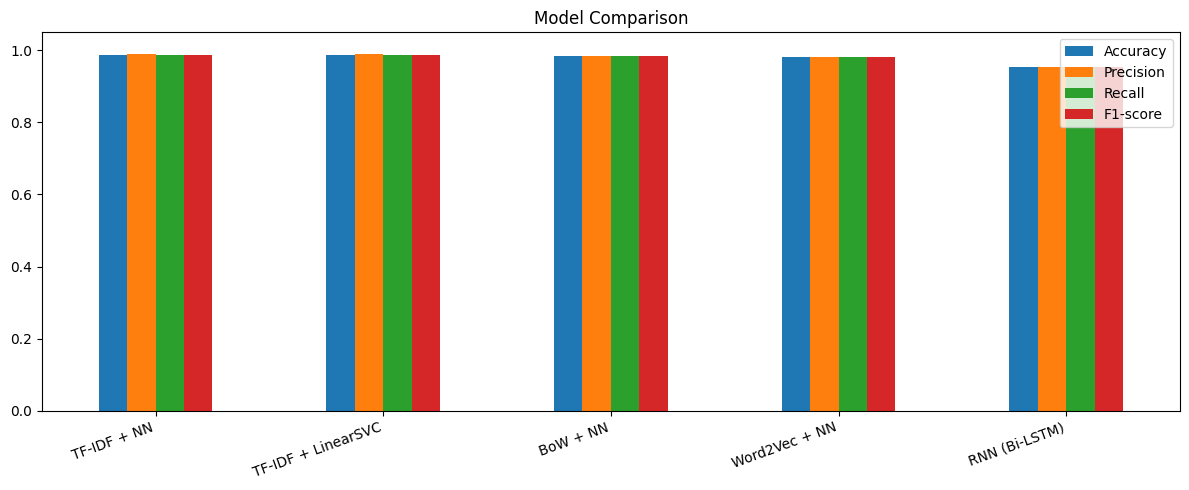

\nBest model on this test split: TF-IDF + NN


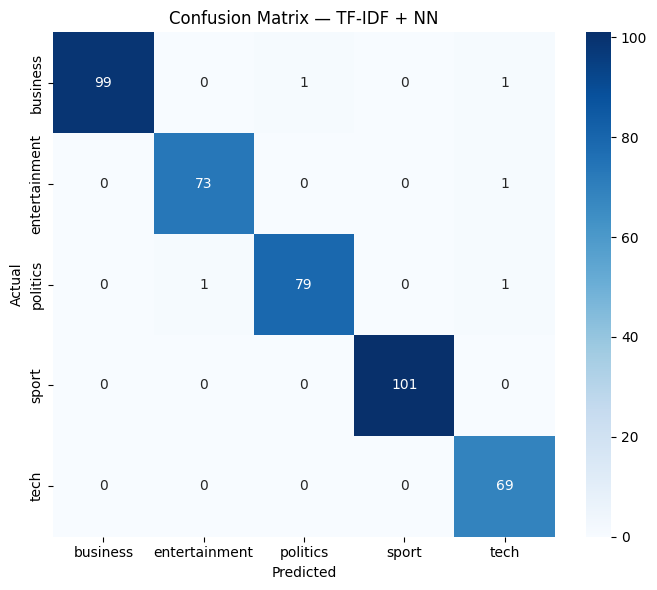

               precision    recall  f1-score   support

     business       1.00      0.98      0.99       101
entertainment       0.99      0.99      0.99        74
     politics       0.99      0.98      0.98        81
        sport       1.00      1.00      1.00       101
         tech       0.96      1.00      0.98        69

     accuracy                           0.99       426
    macro avg       0.99      0.99      0.99       426
 weighted avg       0.99      0.99      0.99       426



In [10]:
# Compare all models
res_df = pd.DataFrame(
    results, index=["Accuracy", "Precision", "Recall", "F1-score"]
).T.sort_values("F1-score", ascending=False)
res_df = res_df.round(4)
print("\\n===== Model Comparison (sorted by F1-score) =====")
print(res_df)
res_df.to_csv("model_comparison.csv")

res_df.plot(kind="bar", figsize=(12, 5))
plt.title("Model Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

# Report the strongest model according to this held-out test set.
best_name = res_df["F1-score"].idxmax()
print("\\nBest model on this test split:", best_name)

if best_name == "TF-IDF + LinearSVC":
    final_pred = svm_pred
elif best_name == "BoW + NN":
    final_pred = np.argmax(nn_bow.predict(X_test_bow, verbose=0), axis=1)
elif best_name == "TF-IDF + NN":
    final_pred = np.argmax(nn_tfidf.predict(X_test_tfidf, verbose=0), axis=1)
elif best_name == "Word2Vec + NN":
    final_pred = np.argmax(nn_w2v.predict(X_test_w2v, verbose=0), axis=1)
else:
    final_pred = rnn_pred

cm = confusion_matrix(y_test, final_pred, labels=np.arange(num_classes))
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("best_model_confusion_matrix.png")
plt.show()

print(classification_report(
    y_test, final_pred, labels=np.arange(num_classes),
    target_names=le.classes_, zero_division=0
))


In [11]:
# Save the RNN artifacts
rnn.save("rnn_model.keras")
with open("tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tok.to_json())
with open("config.json", "w", encoding="utf-8") as f:
    json.dump(
        {"classes": [str(c) for c in le.classes_], "max_len": max_len},
        f, ensure_ascii=False, indent=2
)

# Save the best conventional baseline too; it is often the strongest model for this dataset.
import joblib
joblib.dump(tfidf_svm, "tfidf_vectorizer.joblib")
joblib.dump(svm_model, "news_category_svm.joblib")
with open("classes.json", "w", encoding="utf-8") as f:
    json.dump([str(c) for c in le.classes_], f, ensure_ascii=False, indent=2)

print("Saved RNN, tokenizer/config, TF-IDF vectorizer, SVM model, and classes.")


Saved RNN, tokenizer/config, TF-IDF vectorizer, SVM model, and classes.
